## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Edward Christopher

**Date:** October 12

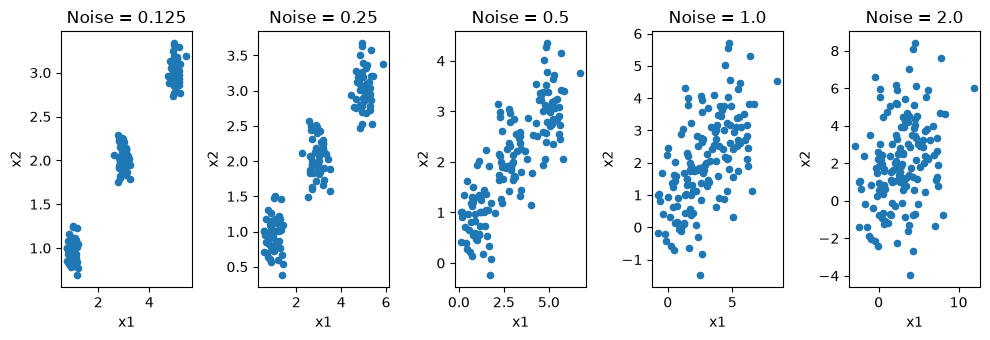

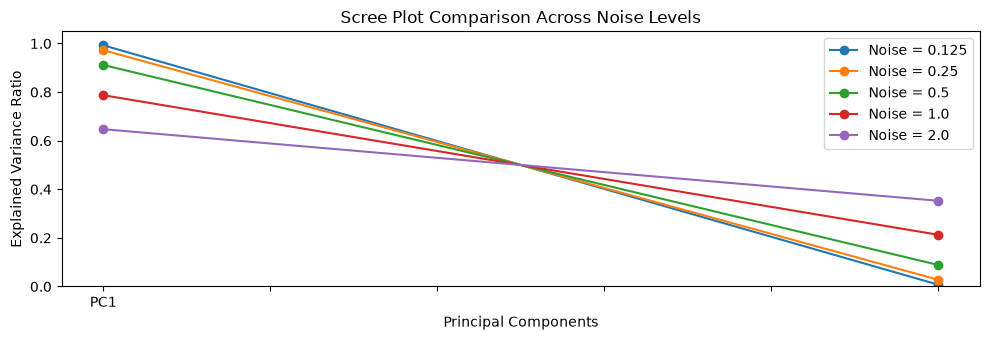

In [ ]:
# Your Phase 1 solution to the problem goes here.


#1. 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#%pip install -U scikit-learn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


#2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up 
# from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

fig, axes = plt.subplots(1, 5, figsize=(10, 3.5))

axes[0].set(title="Noise = 0.125", xlabel="X1", ylabel="X2")
df0_125.plot.scatter(x='x1', y='x2', ax=axes[0])

axes[1].set(title="Noise = 0.25", xlabel="X1", ylabel="X2")
df0_25.plot.scatter(x='x1', y='x2', ax=axes[1])

axes[2].set(title="Noise = 0.5", xlabel="X1", ylabel="X2")
df0_5.plot.scatter(x='x1', y='x2', ax=axes[2])

axes[3].set(title="Noise = 1.0", xlabel="X1", ylabel="X2")
df1_0.plot.scatter(x='x1', y='x2', ax=axes[3])

axes[4].set(title="Noise = 2.0", xlabel="X1", ylabel="X2")
df2_0.plot.scatter(x='x1', y='x2', ax=axes[4])


plt.tight_layout()
plt.show()

# As noise increases from 0.125 to 2.0, the clusters become less concentrated. At 0.125 and 0.25, there are three distinct clusters. 
# However, as noise reaches, 0.5, the clusters are so big they overlap. As the noise increases from 0.5 to 2.0
# the clusters overlap more and they become less destinct. 


#3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot 
# (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. 
# (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
def get_variance(df):
    scaled = StandardScaler().fit_transform(df[['x1', 'x2']])
    return PCA().fit(scaled).explained_variance_ratio_

scree_df = pd.DataFrame({
    'Noise = 0.125': get_variance(df0_125),
    'Noise = 0.25': get_variance(df0_25),
    'Noise = 0.5': get_variance(df0_5),
    'Noise = 1.0': get_variance(df1_0),
    'Noise = 2.0': get_variance(df2_0)
}, index=['PC1', 'PC2'])

fig, ax = plt.subplots(figsize=(10, 3.5))

ax.set(title="Scree Plot Comparison Across Noise Levels", xlabel="Principal Components", ylabel="Explained Variance Ratio", ylim=(0, 1.05))

scree_df.plot(kind='line', marker='o', ax=ax)
plt.tight_layout()
plt.show()

# I don't see any 'clear' elbow. All the scree plots are linear with no distinct curve. I belive this is because 
# only X1 and X2 are being considered, and two points are not enought to find a distinct elbow.  
# As noise increases the slope of each plot becomes less negative.

#4. Explain the intuition of the elbow, using this numerical simulation as an example.

# The elbow method looks for the point where adding more principal components provides less additional explained variance.
# In this example, at low noise levels, PC1 explains more variance than PC2. As noise increases, 
# the variance becomes more evenly distributed between the two components, making it harder to identify 
# a clear elbow. This shows how increasing noise makes it more difficult to determine how many 
# components should be retained.




173
148


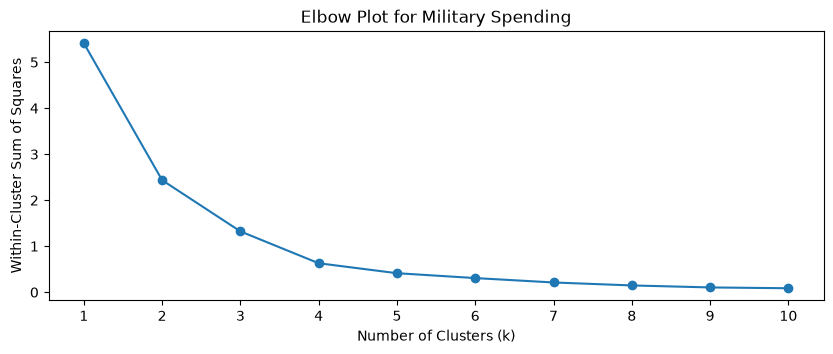

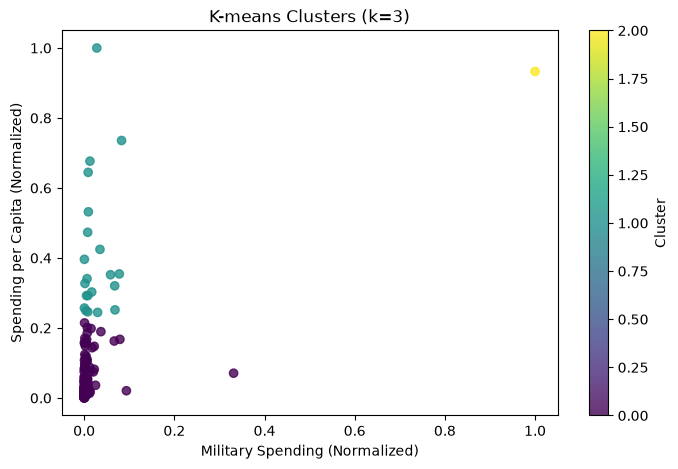

Spending (2020 USD)                                                   \
                      count      mean       std      min       25%       50%   
cluster                                                                        
0                     126.0  0.007624  0.031936  0.00000  0.000198  0.000735   
1                      21.0  0.025652  0.027942  0.00051  0.006387  0.009329   
2                       1.0  1.000000       NaN  1.00000  1.000000  1.000000   

                            Spending per Capita                                \
              75%       max               count      mean       std       min   
cluster                                                                         
0        0.004133  0.331409               126.0  0.048200  0.055576  0.000000   
1        0.035063  0.082927                21.0  0.415051  0.199075  0.244571   
2        1.000000  1.000000                 1.0  0.933024       NaN  0.933024   

                                                 
              25%       50%       75%       max  
cluster                                          
0        0.007114  0.023108  0.074477  0.214529  
1        0.292525  0.341017  0.473454  1.000000  
2        0.933024  0.933024  0.933024  0.933024

,Country,cluster
5540,United States of America,2


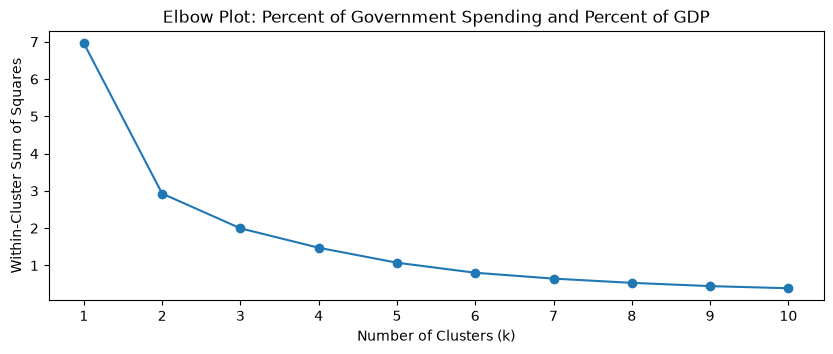

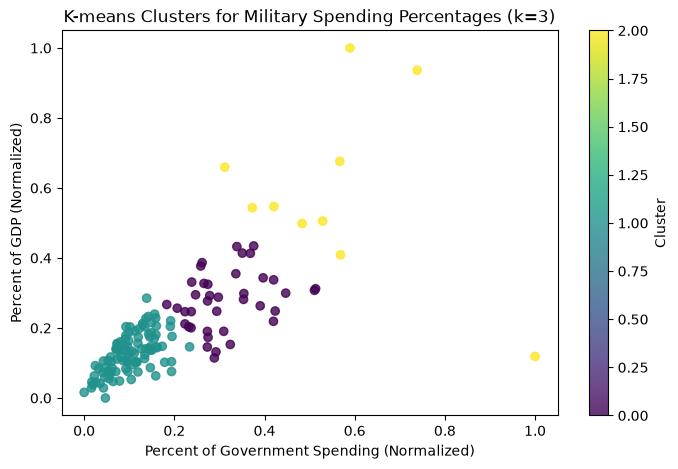

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 99.0  0.035777  0.014549  0.004896   
2                                 10.0  0.171289  0.058725  0.097882   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1        0.005681  0.000054  0.008393  0.013191  0.016752  0.028132  
2        0.024867  0.011742  0.049297  0.053729  0.066190  0.098470

,Country,cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,0,0.081976,0.037179


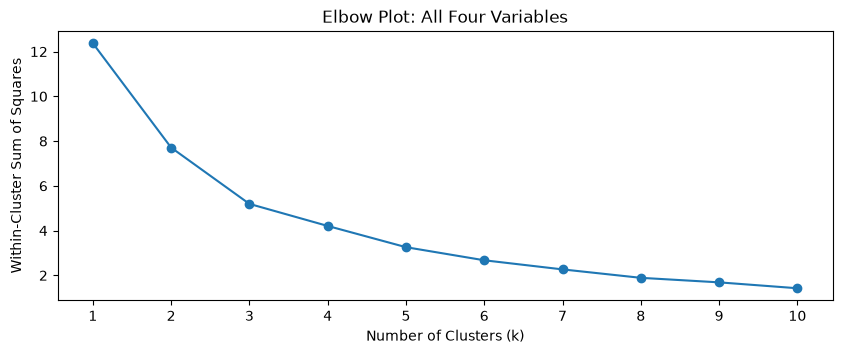

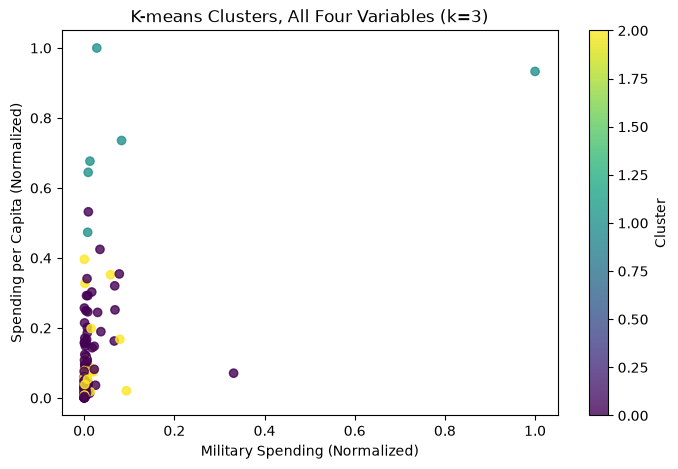

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      31.0    8786.086602   17901.909108   162.373364   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         467.787851   1404.787234   7739.166193   72937.064048   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                     111.0   196.926833  ...                       0.050505   
1                       6.0  1875.150751  ...                       0.164503   
2                      31.0   212.689100  ...                       0.134663   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.303027           31.0  0.033492  0.011449  0.011742  0.027560   

                                       
              50%       75%       max  
cluster                                
0        0.013589  0.017769  0.028132  
1        0.059257  0.085398  0.098470  
2        0.032024  0.040531  0.066600  

[3 rows x 32 columns]

,Country,cluster
5540,United States of America,1


cluster
0    111
2     31
1      6
Name: count, dtype: int64
0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Latvia', 'Lesotho', 'Liberia', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Netherlands', 'New Zealand', 'Nicaragua', 'Niger', 'Nigeria', 

In [20]:

#**Q2.** This question is a case study on clustering.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans


#1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. 
#   This has data about military spending by country. Filter the rows to select only the year 2020,
#   and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?

df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')
df.head()
df_2020 = df[df['Year'] == 2020].copy()
print (len(df_2020))
df_clean = df_2020[df_2020['Spending (2020 USD)'].notna() & df_2020['Percent of GDP'].notna() & df_2020['Percent of Government Spending'].notna() & df_2020['Spending per Capita'].notna()].copy()
print (len(df_clean))

#I got 148 too and I don't see any more ways to clean the variables

#2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine 
#   the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` 
#   and `Spending per Capita`, and hue the dots by their cluster membership. Compute a 
#   describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? 
#   Where is the United States? Do you notice any patterns in the cluster membership?
cols = ['Spending (2020 USD)', 'Spending per Capita']
scaler = MinMaxScaler()
df_clean_2 = df_clean.copy()
df_clean_2[cols] = scaler.fit_transform(df_clean[cols])

#I got the previous code from a previous lab, the following code is from Github.

inertias = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans.fit(df_clean_2[cols])
    inertias.append(kmeans.inertia_)

# Plot the elbow plot
plt.figure(figsize=(10, 3.5))
plt.plot(K, inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Elbow Plot for Military Spending')
plt.xticks(list(K))
plt.show()
#It looks like the elbow happens at k=3.

k = 3  

kmeans = KMeans(n_clusters=k, random_state=100, n_init=10)

df_clean_2['cluster'] = kmeans.fit_predict(df_clean_2[cols])

plt.figure(figsize=(8, 5))
plt.scatter(
    df_clean_2['Spending (2020 USD)'],
    df_clean_2['Spending per Capita'],
    c=df_clean_2['cluster'],
    cmap='viridis',
    alpha=0.8
)
plt.xlabel('Military Spending (Normalized)')
plt.ylabel('Spending per Capita (Normalized)')
plt.title(f'K-means Clusters (k={k})')
plt.colorbar(label='Cluster')
plt.show()

# Describe table conditional on cluster membership
display(
    df_clean_2.groupby('cluster')[
        ['Spending (2020 USD)', 'Spending per Capita']
    ].describe()
)

# Find the United States
display(
    df_clean_2.loc[
        df_clean_2['Country'].str.contains(
            'United States', case=False, na=False
        ),
        ['Country', 'cluster']
    ]
)

# The clusters appear to separate countries based on their military spending. 
# Cluster 0 contains most countries (126), which generally have lower total spending and spending per capita. 
# Cluster 1 contains 21 countries with higher spending per capita. Cluster 2 contains only the United States, 
# which has the highest total military spending and very high spending per capita. This suggests that 
# the United States is an outlier in terms of military spending compared to the other countries. Overall, 
# the clusters appear to distinguish countries with lower spending from those with higher per-capita spending, 
# while separating the United States due to its  high total spending.


#3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
cols = ['Percent of Government Spending', 'Percent of GDP']
scaler3 = MinMaxScaler()
df_clean_3 = df_clean.copy()
df_clean_3[cols] = scaler3.fit_transform(df_clean_3[cols])

inertias3 = []
K = range(1, 11)

for k in K:
    kmeans3 = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans3.fit(df_clean_3[cols])
    inertias3.append(kmeans3.inertia_)

plt.figure(figsize=(10, 3.5))
plt.plot(K, inertias3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Elbow Plot: Percent of Government Spending and Percent of GDP')
plt.xticks(list(K))
plt.show()

#4 looks like the elbow
k3 = 3

# Run K-means and assign cluster membership
kmeans3 = KMeans(n_clusters=k3, random_state=100, n_init=10)
df_clean_3['cluster'] = kmeans3.fit_predict(df_clean_3[cols])

# Scatterplot colored by cluster membership
plt.figure(figsize=(8, 5))
plt.scatter(
    df_clean_3['Percent of Government Spending'],
    df_clean_3['Percent of GDP'],
    c=df_clean_3['cluster'],
    cmap='viridis',
    alpha=0.8
)
plt.xlabel('Percent of Government Spending (Normalized)')
plt.ylabel('Percent of GDP (Normalized)')
plt.title(f'K-means Clusters for Military Spending Percentages (k={k3})')
plt.colorbar(label='Cluster')
plt.show()

# Describe the ORIGINAL values within each cluster
df_clean_3['cluster'] = df_clean_3['cluster'].astype('category')

df_clean_3_labeled = df_clean.copy()
df_clean_3_labeled['cluster'] = df_clean_3['cluster'].values

display(
    df_clean_3_labeled.groupby('cluster')[
        ['Percent of Government Spending', 'Percent of GDP']
    ].describe()
)

# Find the United States and its cluster
display(
    df_clean_3_labeled.loc[
        df_clean_3_labeled['Country'].str.contains(
            'United States', case=False, na=False
        ),
        ['Country', 'cluster',
         'Percent of Government Spending', 'Percent of GDP']
    ]
)
# The clusters appear to separate countries based on how much they prioritize military spending. 
# Cluster 1 contains most countries (99) and has the lowest average percentages of 
# government spending and GDP devoted to the military. Cluster 0 contains 39 countries with 
# higher percentages, while cluster 2 contains 10 countries with the highest average percentages. 
# The United States is in cluster 0, suggesting that its military spending as a 
# share of government spending and GDP is relatively high, but not as high as the average for cluster 2. 
# Compared to part 2, the United States is no longer in its own cluster because these variables
# measure the relative priority of military spending rather than total spending amounts.


#4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, 
# ` Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. 
#   How do your results compare to the previous two parts? 

cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']
scaler4 = MinMaxScaler()
df_clean_4 = df_clean.copy()
df_clean_4[cols] = scaler4.fit_transform(df_clean_4[cols])

inertias4 = []
K = range(1, 11)

for k in K:
    kmeans4 = KMeans(n_clusters=k, random_state=100, n_init=10)
    kmeans4.fit(df_clean_4[cols])
    inertias4.append(kmeans4.inertia_)

plt.figure(figsize=(10, 3.5))
plt.plot(K, inertias4, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Elbow Plot: All Four Variables')
plt.xticks(list(K))
plt.show()

# Pick k from the elbow you see, then update this number
k4 = 3

kmeans4 = KMeans(n_clusters=k4, random_state=100, n_init=10)
df_clean_4['cluster'] = kmeans4.fit_predict(df_clean_4[cols])

# Scatterplot (can only show 2 of the 4 variables), colored by cluster
plt.figure(figsize=(8, 5))
plt.scatter(
    df_clean_4['Spending (2020 USD)'],
    df_clean_4['Spending per Capita'],
    c=df_clean_4['cluster'],
    cmap='viridis',
    alpha=0.8
)
plt.xlabel('Military Spending (Normalized)')
plt.ylabel('Spending per Capita (Normalized)')
plt.title(f'K-means Clusters, All Four Variables (k={k4})')
plt.colorbar(label='Cluster')
plt.show()

# Describe the ORIGINAL values within each cluster
df_clean_4_labeled = df_clean.copy()
df_clean_4_labeled['cluster'] = df_clean_4['cluster'].values

display(
    df_clean_4_labeled.groupby('cluster')[
        ['Spending (2020 USD)', 'Spending per Capita',
         'Percent of Government Spending', 'Percent of GDP']
    ].describe()
)

# Find the United States and its cluster
display(
    df_clean_4_labeled.loc[
        df_clean_4_labeled['Country'].str.contains(
            'United States', case=False, na=False
        ),
        ['Country', 'cluster']
    ]
)

# Cluster sizes and members, to look for patterns
print(df_clean_4_labeled['cluster'].value_counts())
for c in sorted(df_clean_4_labeled['cluster'].unique()):
    print(c, list(df_clean_4_labeled.loc[df_clean_4_labeled['cluster'] == c, 'Country']))

# Using all four variables combines total spending with relative spending. 
# The clusters may differ from parts 2 and 3 because more information is considered. 
# The United States may still stand out due to its high total military spending.


#5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

# K-means found some useful patterns by grouping countries with similar military spending.
# However, the results depend on which variables are used, and some clusters may not be very distinct or meaningful.



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 
- **AI tool and model used**

### *Prompts used

1. [Paste prompt]


2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [19]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]